# MLP sample analysis

Compare generated MLP sequences with the real and shuffled control sets using the evaluation CSVs. This notebook reads results produced by the project scripts; it does not train or sample sequences.

Run `uv run python generate.py`, then evaluate the generated samples and controls with `eval/eval.py` before running these cells.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
if (cwd / "results/eval").is_dir():
    ROOT = cwd
elif (cwd.parent / "results/eval").is_dir():
    ROOT = cwd.parent
else:
    raise FileNotFoundError("Run this notebook from the project root or its notebooks/ directory")

evaluation_files = {
    "MLP": ROOT / "results/eval/mlp_samples/eval.csv",
    "Real control": ROOT / "results/eval/control_real/eval.csv",
    "Shuffled control": ROOT / "results/eval/control_shuffled/eval.csv",
}
missing = [str(path) for path in evaluation_files.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing evaluation CSV(s): " + ", ".join(missing) + ". Run `uv run python generate.py`, "
        "then `uv run python eval/make_controls.py --num 256` and evaluate each CSV with "
        "`uv run python eval/eval.py --samples <csv>`."
    )

evaluations = {name: pd.read_csv(path) for name, path in evaluation_files.items()}
[(name, len(frame), list(frame.columns)) for name, frame in evaluations.items()]

[('MLP',
  256,
  ['id',
   'length',
   'valid',
   'nearest_identity',
   'is_unique',
   'mean_plddt',
   'pdb',
   'sequence']),
 ('Real control',
  256,
  ['id',
   'length',
   'valid',
   'nearest_identity',
   'is_unique',
   'mean_plddt',
   'pdb',
   'sequence']),
 ('Shuffled control',
  256,
  ['id',
   'length',
   'valid',
   'nearest_identity',
   'is_unique',
   'mean_plddt',
   'pdb',
   'sequence'])]

## Sequence-level comparison

`nearest_identity` measures similarity to the training set. Low identity alone is not evidence of good proteins: random or shuffled sequences can also be novel. Compare the MLP against both controls.

In [2]:
summary = pd.DataFrame.from_dict(
    {
        name: {
            "n": len(frame),
            "valid_fraction": frame["valid"].mean(),
            "unique_fraction": frame["is_unique"].mean(),
            "median_nearest_identity": frame["nearest_identity"].median(),
            "median_length": frame["length"].median(),
        }
        for name, frame in evaluations.items()
    },
    orient="index",
).rename_axis("set")
summary

,n,valid_fraction,unique_fraction,median_nearest_identity,median_length
set,,,,,
MLP,256,1.0,1.0,0.26584,92.0
Real control,256,1.0,1.0,0.69946,92.0
Shuffled control,256,1.0,1.0,0.25000,92.0


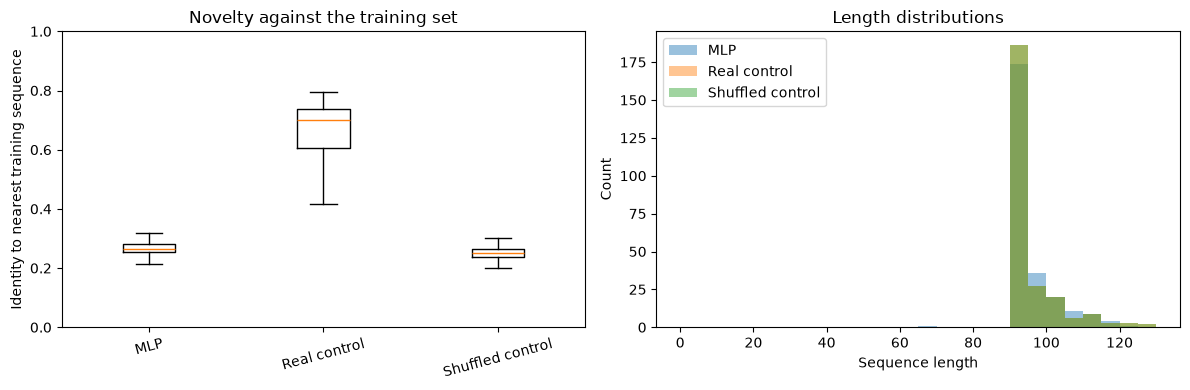

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = list(evaluations)

identity_values = [frame["nearest_identity"].dropna().to_numpy() for frame in evaluations.values()]
axes[0].boxplot(identity_values, showfliers=False)
axes[0].set_xticks(range(1, len(names) + 1), names, rotation=15)
axes[0].set_ylabel("Identity to nearest training sequence")
axes[0].set_ylim(0, 1)
axes[0].set_title("Novelty against the training set")

bins = np.arange(0, 131, 5)
for name, frame in evaluations.items():
    axes[1].hist(frame["length"], bins=bins, alpha=0.45, label=name)
axes[1].set_xlabel("Sequence length")
axes[1].set_ylabel("Count")
axes[1].set_title("Length distributions")
axes[1].legend()

fig.tight_layout()

## Folding confidence (optional)

After ESMFold evaluation, the CSVs include `mean_plddt`. Fold the MLP samples and both controls on a suitable GPU before comparing them. The cluster helper also writes structure figures:

```bash
bash hpc/run_eval.sh results/sequences/mlp_samples.csv
```

Run the helper for each control CSV as well if you want all three sets in the pLDDT plot.

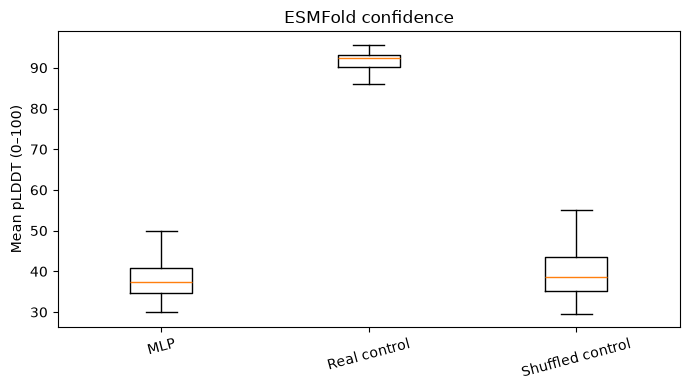

In [4]:
folded = {name: frame for name, frame in evaluations.items() if "mean_plddt" in frame.columns}
if not folded:
    print("No folding results yet. Run the ESMFold evaluation command in the preceding cell.")
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    names = list(folded)
    plddt_values = [frame["mean_plddt"].dropna().to_numpy() for frame in folded.values()]
    ax.boxplot(plddt_values, showfliers=False)
    ax.set_xticks(range(1, len(names) + 1), names, rotation=15)
    ax.set_ylabel("Mean pLDDT (0–100)")
    ax.set_title("ESMFold confidence")
    fig.tight_layout()